# **Lab Report: Shooting method to solve Blasius equation**
<h3 align="RIGHT">Submitted by: Kalyana Raama Bheema<h3>

## Problem statement

For steady, incompressible flow of a uniform stream $U_\infty$ over a flat plate, the similarity variable $\eta = y\sqrt{U_\infty/(\nu x)}$ and $u/U_\infty = f'(\eta)$ turn the boundary layer equations into the **Blasius equation**:

$$f''' + \tfrac{1}{2} f f'' = 0, \qquad 0 < \eta < \infty$$

with boundary conditions

$$f(0) = 0, \qquad f'(0) = 0, \qquad f'(\eta) \to 1 \text{ as } \eta \to \infty$$

This is a **boundary value problem (BVP)**: two conditions are at $\eta = 0$ and one is at $\eta = \infty$. Runge–Kutta methods can only solve **initial value problems (IVPs)**, where all conditions are given at the start.

The **shooting method** fixes this: we guess the missing starting value, integrate forward, check how far we miss the condition at infinity, and correct the guess until we hit it.

In [6]:
# do not change line below
#from google.colab import files

# import required packages here
import numpy as np
import matplotlib.pyplot as plt

## Step (a): Write the equation as a first-order system

The Blasius equation is third order, but Runge–Kutta works on first-order equations. So we define a vector

$$\mathbf{Y} = \begin{pmatrix} Y_1 \\ Y_2 \\ Y_3 \end{pmatrix} = \begin{pmatrix} f \\ f' \\ f'' \end{pmatrix}$$

and differentiate each component:

- $Y_1' = f' = Y_2$
- $Y_2' = f'' = Y_3$
- $Y_3' = f''' = -\tfrac{1}{2} f f'' = -\tfrac{1}{2} Y_1 Y_3$ (from the Blasius equation)

So the system is

$$\mathbf{Y}' = \mathbf{G}(\mathbf{Y}) = \begin{pmatrix} Y_2 \\ Y_3 \\ -\tfrac{1}{2} Y_1 Y_3 \end{pmatrix}$$


In [2]:
def G(Y):
    f, df, d2f = Y               # f, f', f''
    return np.array([df, d2f, -0.5 * f * d2f])

### Now, The RK3 and RK4 steps

**RK3**, Third order Runge Kutta Method With step size $h = \Delta\eta$:

$$k_1 = G(Y_n), \quad k_2 = G\left(Y_n + \tfrac{h}{2}k_1\right), \quad k_3 = G\left(Y_n - h k_1 + 2h k_2\right)$$
$$Y_{n+1} = Y_n + \tfrac{h}{6}\left(k_1 + 4k_2 + k_3\right)$$

Runge-Kutta's RK3 is third-order accurate: halving $h$ reduces the error by a factor of 8. It requires three evaluations of $f$ per step.

**RK4**, Fourth order Runge-Kutta Method With step size $h = \Delta\eta$:

$$k_1 = G(Y_n), \quad k_2 = G\left(Y_n + \tfrac{h}{2}k_1\right), \quad k_3 = G\left(Y_n + \tfrac{h}{2}k_2\right), \quad k_4 = G(Y_n + h k_3)$$
$$Y_{n+1} = Y_n + \tfrac{h}{6}\left(k_1 + 2k_2 + 2k_3 + k_4\right)$$

Runge-Kutta's RK4 is fourth-order accurate: halving $h$ reduces the error by a factor of 16. It requires four evaluations of $f$ per step.

In [3]:
def rk3_step(Y, h):
    k1 = G(Y)
    k2 = G(Y + h/2 * k1)
    k3 = G(Y - h*k1 + 2*h*k2)
    return Y + h/6 * (k1 + 4*k2 + k3)

def rk4_step(Y, h):
    k1 = G(Y)
    k2 = G(Y + h/2 * k1)
    k3 = G(Y + h/2 * k2)
    k4 = G(Y + h * k3)
    return Y + h/6 * (k1 + 2*k2 + 2*k3 + k4)

## Step (b): The missing initial condition

To start an IVP for a third-order equation we need three values at $\eta = 0$: $f(0)$, $f'(0)$, and $f''(0)$.

We know $f(0) = 0$ and $f'(0) = 0$, but **$f''(0)$ is not given**. Instead we are given $f'(\infty) = 1$.

So the missing initial condition is $f''(0)$, and we call it the **shooting parameter**:

$$s = f''(0)$$

For any guess of $s$, the starting vector is $\mathbf{Y}(0) = (0,\ 0,\ s)$, and we can integrate forward like a normal IVP.
Physically, $f''(0)$ is proportional to the wall shear stress (friction on the plate), so it is the most important number in this problem.

In [7]:
def solve_ivp(s, h, eta_inf, step):
    n = round(eta_inf / h)                  # number of steps
    eta = np.linspace(0, eta_inf, n + 1)
    Y = np.zeros((n + 1, 3))
    Y[0] = [0.0, 0.0, s]                    # f(0)=0, f'(0)=0, f''(0)=s
    for i in range(n):
        Y[i+1] = step(Y[i], h)
    return eta, Y

Let's try trial and error method to see what "shooting" looks like. If 
s is too small, $f'$ ends below 1, if s is too large then $f'$ ends above 1 that implies the correct value of s lies in between

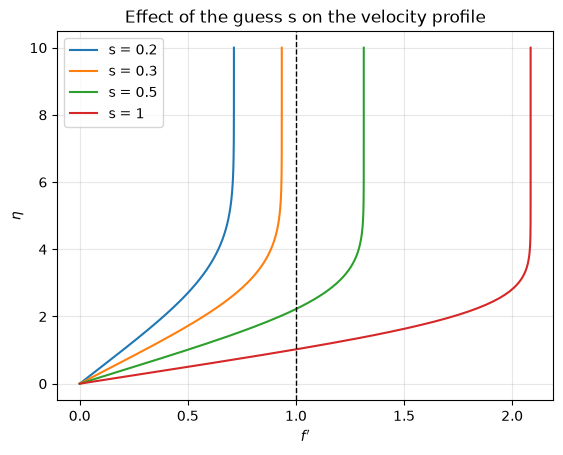

In [10]:
for s_guess in [0.2, 0.3, 0.5, 1]:
    eta, Y = solve_ivp(s_guess, 0.05, 10, rk4_step)
    plt.plot(Y[:, 1], eta, label=f"s = {s_guess}")

plt.axvline(1, color='k', ls='--', lw=1)
plt.ylabel(r'$\eta$'); plt.xlabel(r"$f'$")
plt.title('Effect of the guess s on the velocity profile')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

As we can see from the graph the $s$ or $f''$ value lies between 0.3 and 0.5 from this trial and error method.

## Step (c): Choose $\eta_\infty$, define the residual, and solve for $s$

### Choosing $\eta_\infty$

We need to take a $\eta_\infty$ value where beyond this value flow is basically free stream. we normally choose
$$\eta_\infty = 10$$
### The residual
For a guess $s$, the residual measures how badly we miss the far-field condition:
$$F(s;\eta_\infty) = f'(\eta_\infty; s) - 1$$
The correct $s$ is the **root** of $F(s) = 0$.

In [1]:
def F(s, h, eta_inf, step):
    eta, Y = solve_ivp(s, h, eta_inf, step)
    return Y[-1, 1] - 1.0          # f'(eta_inf) - 1

### Root finding with the bisection method

The **bisection method** is the simplest and safest root finder. The idea:

1. Find two values $a$ and $b$ where $F(a)$ and $F(b)$ have **opposite signs**. Then the root must lie between them (this is called a *bracket*).
2. Take the midpoint $c = (a+b)/2$ and compute $F(c)$.
3. Keep the half that still has a sign change:
   - if $F(a)$ and $F(c)$ have opposite signs, the root is in $[a, c]$, so set $b = c$;
   - otherwise the root is in $[c, b]$, so set $a = c$.
4. Repeat until the interval is small enough.

**Tolerance:** We stop when the half-width of the interval is below $10^{-12}$. Because the root is always inside the interval.\
**Iterations:** After $k$ iterations the half-width is $(b-a)/2^{k+1}$. Setting $0.9/2^{k+1} < 10^{-12}$ gives $k \approx 39$ iterations.


In [3]:
def bisection(h, eta_inf, step, a=0.2, b=1.0, tol=1e-12):
    Fa = F(a, h, eta_inf, step)
    Fb = F(b, h, eta_inf, step)
    if Fa * Fb > 0:
        raise ValueError("F(a) and F(b) have the same sign: no bracket")
    it = 0
    while (b - a) / 2 > tol:
        c = (a + b) / 2
        Fc = F(c, h, eta_inf, step)
        if Fa * Fc < 0:      # root is in [a, c]
            b = c
        else:                # root is in [c, b]
            a, Fa = c, Fc
        it += 1
    return (a + b) / 2, it